In [1]:
from pathlib import Path
import pandas as pd

# Dataset directory
DATA_DIR = Path(
    r"C:\B-TECH\ACADEMIC\MLLAB\ML_PROJECT\AI_Career_Guidance_Dataset_Package\AI_Career_Guidance_Dataset"
)

# Display available files
print("Dataset directory exists:", DATA_DIR.exists())
print("\nAvailable files:")

for file in sorted(DATA_DIR.iterdir()):
    print(file.name)

# Load processed dataset
data_path = DATA_DIR / "career_guidance_processed.csv"
df = pd.read_csv(data_path)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset directory exists: True

Available files:
.ipynb_checkpoints
01_Career_Guidance_EDA.ipynb
career_guidance_processed.csv
career_guidance_raw_synthetic.csv
career_guidance_test.csv
career_guidance_train.csv
data_dictionary.json
dataset_summary.csv
README.md

Dataset loaded successfully!
Shape: (2400, 27)


,profile_id,age_group,education_level,experience_stage,region_type,interest_technology,interest_data,interest_problem_solving,interest_creativity,interest_people,...,trait_conscientiousness,trait_extraversion,trait_agreeableness,trait_emotional_stability,skill_programming,skill_data_analysis,skill_research,skill_communication,skill_leadership,recommended_career_domain
0,CG00001,15-18,B.Sc Mathematics,1-3 years,Rural,0.588889,1.000000,0.955556,0.311111,0.322222,...,0.955556,0.744444,0.533333,0.611111,0.488889,1.000000,0.544444,0.633333,0.422222,Data Science & Analytics
1,CG00002,15-18,B.Sc Mathematics,Student,Rural,0.488889,0.988889,0.622222,0.633333,0.744444,...,0.644444,0.422222,0.877778,0.777778,0.655556,0.766667,0.600000,0.577778,0.711111,Finance & Accounting
2,CG00003,31+,B.Tech Mechanical,Student,Rural,0.788889,0.833333,0.888889,0.288889,0.500000,...,0.722222,0.577778,0.755556,0.666667,0.922222,0.600000,0.577778,0.722222,0.411111,Engineering & Core Technology
3,CG00004,23-30,B.Tech Mechanical,Student,Semi-urban,0.866667,0.800000,0.900000,0.477778,0.588889,...,0.855556,0.477778,0.666667,0.633333,0.866667,0.788889,0.644444,0.477778,0.433333,Engineering & Core Technology
4,CG00005,15-18,BBA,Entry-level,Semi-urban,0.488889,0.633333,0.500000,0.711111,1.000000,...,0.511111,0.844444,0.811111,0.688889,0.277778,0.566667,0.455556,0.822222,0.888889,Business & Management


## Next step: EDA — Exploratory Data Analysis

In [2]:
# Display dataset information
df.info()

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   profile_id                  2400 non-null   str    
 1   age_group                   2400 non-null   str    
 2   education_level             2400 non-null   str    
 3   experience_stage            2400 non-null   str    
 4   region_type                 2400 non-null   str    
 5   interest_technology         2400 non-null   float64
 6   interest_data               2400 non-null   float64
 7   interest_problem_solving    2400 non-null   float64
 8   interest_creativity         2400 non-null   float64
 9   interest_people             2400 non-null   float64
 10  interest_helping            2400 non-null   float64
 11  aptitude_logical            2400 non-null   float64
 12  aptitude_numerical          2400 non-null   float64
 13  aptitude_verbal             2400 non-null   

,Data Type
profile_id,str
age_group,str
education_level,str
experience_stage,str
region_type,str
interest_technology,float64
interest_data,float64
interest_problem_solving,float64
interest_creativity,float64
interest_people,float64


In [3]:
# Check missing values
print("Missing Values in Each Column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("Total Missing Values:", df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate profile IDs
print("Duplicate Profile IDs:", df["profile_id"].duplicated().sum())

Missing Values in Each Column:


,Missing Values
profile_id,0
age_group,0
education_level,0
experience_stage,0
region_type,0
interest_technology,0
interest_data,0
interest_problem_solving,0
interest_creativity,0
interest_people,0


Total Missing Values: 0
Duplicate Rows: 0
Duplicate Profile IDs: 0


,Number of Profiles
recommended_career_domain,
UI/UX Design,211
Law & Public Service,208
Education & Research,207
Healthcare & Life Sciences,207
Software Development,205
Data Science & Analytics,201
Engineering & Core Technology,200
Business & Management,200
Digital Marketing,196


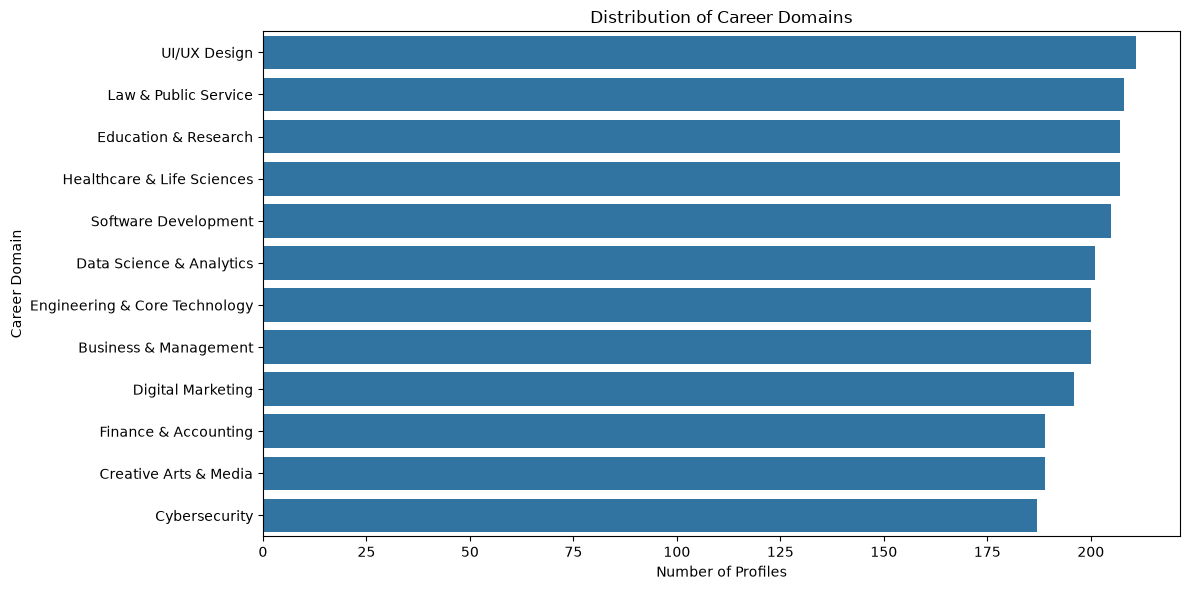

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count records for each career domain
career_counts = df["recommended_career_domain"].value_counts()

display(career_counts.to_frame(name="Number of Profiles"))

# Visualize career domain distribution
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    y="recommended_career_domain",
    order=career_counts.index
)
plt.title("Distribution of Career Domains")
plt.xlabel("Number of Profiles")
plt.ylabel("Career Domain")
plt.tight_layout()
plt.show()

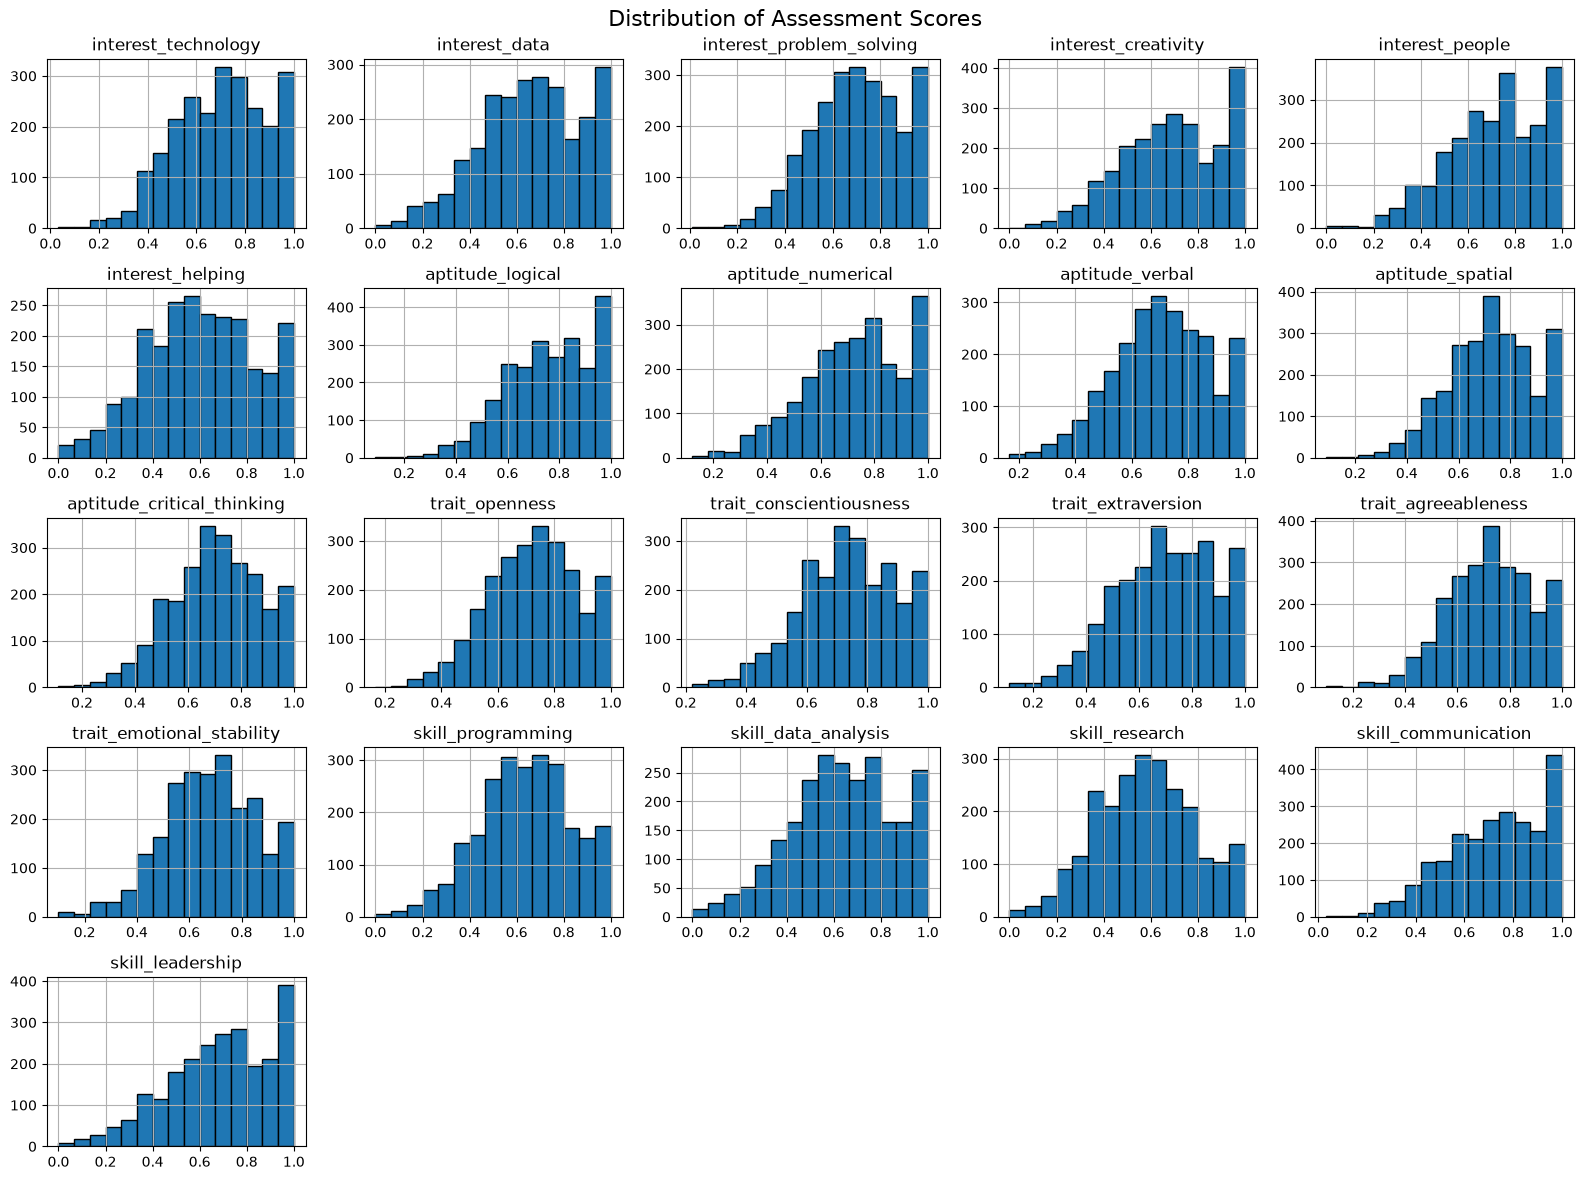

In [5]:
# Select numeric assessment features
numeric_features = df.select_dtypes(include="number").columns.tolist()

# Exclude profile ID because it is an identifier, not an assessment score
numeric_features.remove("profile_id") if "profile_id" in numeric_features else None

# Plot distributions of assessment features
df[numeric_features].hist(
    figsize=(16, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Assessment Scores", fontsize=16)
plt.tight_layout()
plt.show()

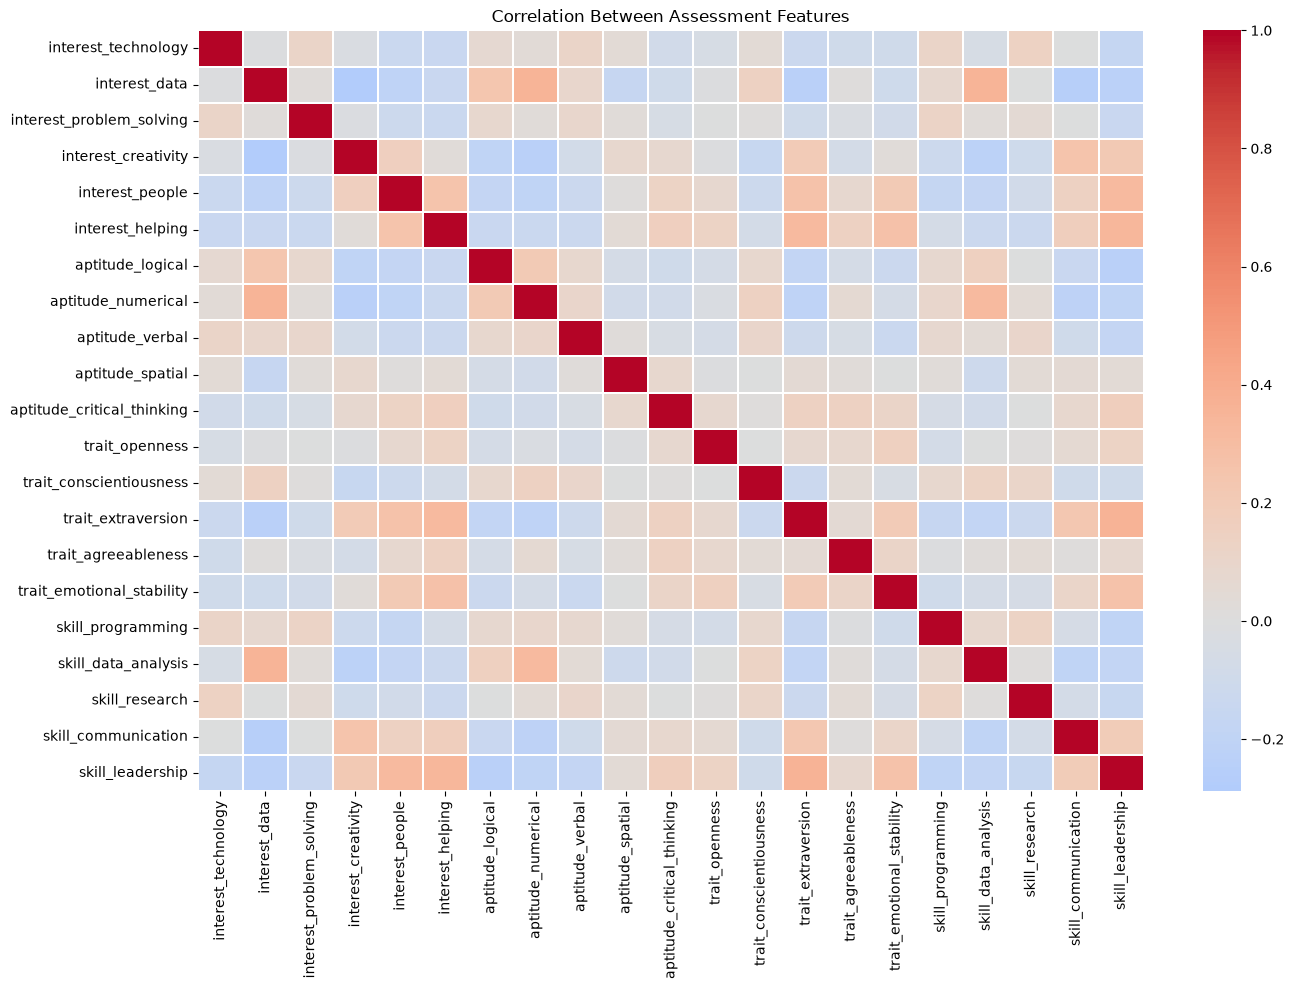

In [6]:
# Select assessment features only
assessment_features = [
    col for col in numeric_features
    if col.startswith(("interest_", "aptitude_", "trait_", "skill_"))
]

# Calculate correlations
correlation_matrix = df[assessment_features].corr()

# Visualize correlations
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Between Assessment Features")
plt.tight_layout()
plt.show()

In [7]:
# Summary statistics for assessment features
display(df[assessment_features].describe().T)

# Average assessment scores for each career domain
career_profile_summary = df.groupby(
    "recommended_career_domain"
)[assessment_features].mean().round(3)

display(career_profile_summary)

,count,mean,std,min,25%,50%,75%,max
interest_technology,2400.0,0.699741,0.191172,0.033333,0.566667,0.700000,0.844444,1.0
interest_data,2400.0,0.657940,0.217203,0.000000,0.500000,0.655556,0.822222,1.0
interest_problem_solving,2400.0,0.702843,0.187728,0.011111,0.577778,0.700000,0.844444,1.0
interest_creativity,2400.0,0.685657,0.214727,0.000000,0.533333,0.688889,0.866667,1.0
interest_people,2400.0,0.708509,0.201003,0.000000,0.566667,0.722222,0.866667,1.0
interest_helping,2400.0,0.601139,0.228154,0.000000,0.444444,0.594444,0.766667,1.0
aptitude_logical,2400.0,0.760958,0.168362,0.088889,0.644444,0.766667,0.900000,1.0
aptitude_numerical,2400.0,0.724569,0.185442,0.122222,0.600000,0.733333,0.866667,1.0
aptitude_verbal,2400.0,0.700315,0.171347,0.166667,0.588889,0.700000,0.822222,1.0
aptitude_spatial,2400.0,0.727620,0.164874,0.088889,0.611111,0.733333,0.844444,1.0


,interest_technology,interest_data,interest_problem_solving,interest_creativity,interest_people,interest_helping,aptitude_logical,aptitude_numerical,aptitude_verbal,aptitude_spatial,...,trait_openness,trait_conscientiousness,trait_extraversion,trait_agreeableness,trait_emotional_stability,skill_programming,skill_data_analysis,skill_research,skill_communication,skill_leadership
recommended_career_domain,,,,,,,,,,,,,,,,,,,,,
Business & Management,0.657,0.558,0.673,0.770,0.780,0.654,0.660,0.667,0.672,0.761,...,0.780,0.764,0.781,0.782,0.764,0.566,0.566,0.557,0.771,0.864
Creative Arts & Media,0.633,0.442,0.663,0.924,0.858,0.687,0.689,0.559,0.664,0.772,...,0.667,0.659,0.866,0.650,0.655,0.581,0.450,0.536,0.845,0.844
Cybersecurity,0.864,0.638,0.762,0.554,0.658,0.437,0.756,0.774,0.781,0.770,...,0.781,0.774,0.566,0.760,0.665,0.698,0.631,0.880,0.640,0.554
Data Science & Analytics,0.759,0.858,0.760,0.684,0.556,0.434,0.863,0.887,0.786,0.674,...,0.665,0.765,0.640,0.659,0.542,0.645,0.865,0.536,0.647,0.560
Digital Marketing,0.665,0.557,0.761,0.861,0.772,0.661,0.678,0.671,0.657,0.771,...,0.769,0.661,0.780,0.781,0.779,0.555,0.573,0.541,0.853,0.765
Education & Research,0.645,0.778,0.670,0.669,0.796,0.764,0.770,0.774,0.666,0.662,...,0.778,0.765,0.759,0.767,0.768,0.677,0.756,0.565,0.756,0.770
Engineering & Core Technology,0.780,0.769,0.764,0.568,0.551,0.461,0.872,0.760,0.777,0.759,...,0.655,0.780,0.545,0.653,0.547,0.778,0.659,0.696,0.563,0.432
Finance & Accounting,0.553,0.874,0.540,0.557,0.680,0.449,0.780,0.863,0.665,0.666,...,0.657,0.773,0.581,0.768,0.676,0.561,0.844,0.534,0.565,0.635
Healthcare & Life Sciences,0.658,0.656,0.675,0.567,0.779,0.765,0.779,0.674,0.664,0.661,...,0.780,0.657,0.773,0.668,0.769,0.548,0.570,0.432,0.656,0.784
